# Deep Q-Learning (DQN) with PyTorch and Gymnasium

*Notebook 3 of the series: value functions → Q-learning → **DQN***

This notebook builds the DQN algorithm (Mnih et al., 2015, *"Human-level control through deep reinforcement learning"*)
step by step. It follows the structure of CleanRL's single-file implementation
[`dqn_atari.py`](https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/dqn_atari.py), with every piece explained.

## From a Q-table to a Q-network

In notebook 2, Q-learning stored one number per (state, action) pair. That breaks down when states are images.
An Atari screen has more possible configurations than any table could hold, and the agent never sees the same
screen twice. So we replace the table with a neural network $Q_\theta(s, a)$ that **generalizes** between similar states.

The update becomes a regression problem. Minimize

$$\mathcal{L}(\theta) = \mathbb{E}_{(s,a,r,s') \sim \mathcal{D}} \Big[ \big( \underbrace{r + \gamma\, (1 - \text{done}) \max_{a'} Q_{\theta^-}(s', a')}_{\text{TD target (no gradient)}} - Q_\theta(s, a) \big)^2 \Big]$$

This is exactly the semi-gradient idea from the value network in notebook 1. On its own, though, it is unstable.
DQN adds **two fixes**:

| Problem | Fix |
|---|---|
| Consecutive frames are highly **correlated**, and SGD assumes independent samples. The network also forgets old experience. | **Experience replay** $\mathcal{D}$: store transitions in a large buffer and train on random mini-batches. |
| The target $r + \gamma \max Q_\theta(s')$ moves every time $\theta$ changes, so we are **chasing our own tail**. | **Target network** $Q_{\theta^-}$: a frozen copy of the network that computes targets and is synced only every *C* steps. |

## Roadmap
1. The building blocks: hyperparameters, Q-network, replay buffer, ε schedule.
2. The training loop, line by line, as in CleanRL.
3. **Part A, CartPole:** trains in a few minutes on a CPU, so you can watch DQN actually learn.
4. **Part B, Atari Breakout:** the full CleanRL setup with all the Atari preprocessing wrappers.

In [25]:
# !pip install "gymnasium[atari]" ale-py torch matplotlib     # uncomment if needed
import random
import time
from collections import defaultdict
from dataclasses import dataclass, replace

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("gymnasium", gym.__version__, "| torch", torch.__version__, "| device:", device)

gymnasium 1.4.0 | torch 2.14.1 | device: cpu


## 1. Hyperparameters

The same `Args` dataclass as CleanRL. The defaults are CleanRL's Atari settings. CleanRL reads these from the
command line with `tyro`; in a notebook we simply create an `Args(...)` object.

In [26]:
@dataclass
class Args:
    env_id: str = "BreakoutNoFrameskip-v4"
    seed: int = 1
    total_timesteps: int = 10_000_000   # agent steps (each one is 4 game frames on Atari)
    learning_rate: float = 1e-4
    buffer_size: int = 1_000_000        # replay memory size
    gamma: float = 0.99                 # discount factor
    tau: float = 1.0                    # target update rate (1.0 = hard copy)
    target_network_frequency: int = 1000  # steps between target-network updates
    batch_size: int = 32
    start_e: float = 1.0                # epsilon at the start...
    end_e: float = 0.01                 # ...decays linearly to this
    exploration_fraction: float = 0.10  # ...over this fraction of total_timesteps
    learning_starts: int = 80_000       # collect this many random steps before learning
    train_frequency: int = 4            # one gradient step every 4 env steps
    optimize_memory_usage: bool = True  # replay-buffer trick (see section 3)

Args()

Args(env_id='BreakoutNoFrameskip-v4', seed=1, total_timesteps=10000000, learning_rate=0.0001, buffer_size=1000000, gamma=0.99, tau=1.0, target_network_frequency=1000, batch_size=32, start_e=1.0, end_e=0.01, exploration_fraction=0.1, learning_starts=80000, train_frequency=4, optimize_memory_usage=True)

## 2. The Q-network

The network takes a state and outputs **one Q-value per action**, all in a single forward pass.
Acting greedily is then just `argmax` over that output.

For Atari this is the "Nature CNN" from the DQN paper. The input is a stack of 4 grayscale 84×84 frames,
so the network can see motion (a single frame can't tell you which way the ball is moving):

| Layer | Output shape |
|---|---|
| input (4 stacked frames) | 4 × 84 × 84 |
| Conv 32 filters, 8×8, stride 4 + ReLU | 32 × 20 × 20 |
| Conv 64 filters, 4×4, stride 2 + ReLU | 64 × 9 × 9 |
| Conv 64 filters, 3×3, stride 1 + ReLU | 64 × 7 × 7 = **3136** |
| Linear 512 + ReLU | 512 |
| Linear → Q-value per action | n_actions |

For CartPole the state is just 4 numbers, so a small MLP is enough.

In [27]:
class QNetwork(nn.Module):
    '''Nature-DQN CNN, identical to CleanRL's dqn_atari.py.'''
    def __init__(self, env):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(3136, 512), nn.ReLU(),
            nn.Linear(512, env.action_space.n),
        )

    def forward(self, x):
        return self.network(x / 255.0)          # pixels 0..255 -> 0..1


class MLPQNetwork(nn.Module):
    '''Small MLP for low-dimensional states such as CartPole.'''
    def __init__(self, env):
        super().__init__()
        n_obs = int(np.prod(env.observation_space.shape))
        self.network = nn.Sequential(
            nn.Linear(n_obs, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, env.action_space.n),
        )

    def forward(self, x):
        return self.network(x)


# shape check with a fake Atari observation
class _FakeEnv:
    action_space = gym.spaces.Discrete(4)
q = QNetwork(_FakeEnv())
print("Q-values for a batch of 2 Atari states:", q(torch.zeros(2, 4, 84, 84)).shape)
print(f"parameters: {sum(p.numel() for p in q.parameters()):,}")

Q-values for a batch of 2 Atari states: torch.Size([2, 4])
parameters: 1,686,180


## 3. The replay buffer

A circular buffer of transitions $(s, a, r, s', \text{terminated})$. When it is full, the oldest entries are
overwritten. `sample()` returns a **random** mini-batch, which breaks the correlation between consecutive steps.

CleanRL uses Stable-Baselines3's `ReplayBuffer`. Here is a self-contained version with the same behavior.

**Memory trick (`optimize_memory_usage`).** On Atari one observation is 4×84×84 bytes, about 28 KB.
Storing both `obs` and `next_obs` for 1M transitions would take about 56 GB. But the `next_obs` of step *t*
is the `obs` of step *t+1*, so we store observations only once and read `next_obs` from the following slot.
- At the end of an episode that slot is later overwritten by the reset observation. That's harmless after a
  real termination, because the target multiplies the next-state value by `(1 - done)`.
- It would be wrong after a *truncation* (time limit). Those are rare on Atari, so we use the trick there but
  not on CartPole, where every successful episode is truncated at 500 steps.

In [28]:
class ReplayBuffer:
    def __init__(self, size, obs_shape, obs_dtype, device, optimize_memory_usage=False):
        self.size, self.device, self.optimize = size, device, optimize_memory_usage
        self.obs = np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.next_obs = None if optimize_memory_usage else np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.actions = np.zeros((size, 1), dtype=np.int64)
        self.rewards = np.zeros(size, dtype=np.float32)
        self.dones = np.zeros(size, dtype=np.float32)
        self.pos, self.full = 0, False

    def add(self, obs, next_obs, action, reward, terminated):
        self.obs[self.pos] = obs
        if self.optimize:
            self.obs[(self.pos + 1) % self.size] = next_obs     # next_obs lives in the next slot
        else:
            self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = action
        self.rewards[self.pos] = reward
        self.dones[self.pos] = terminated                     # only TRUE terminations stop bootstrapping
        self.pos = (self.pos + 1) % self.size
        self.full = self.full or self.pos == 0

    def __len__(self):
        return self.size if self.full else self.pos

    def sample(self, batch_size):
        if self.optimize and self.full:
            # skip slot `pos`: its obs was just overwritten by the newest next_obs
            idx = (np.random.randint(1, self.size, size=batch_size) + self.pos) % self.size
        else:
            idx = np.random.randint(0, len(self), size=batch_size)
        next_obs = self.obs[(idx + 1) % self.size] if self.optimize else self.next_obs[idx]
        t = lambda x: torch.as_tensor(x, device=self.device)
        return (t(self.obs[idx]).float(), t(self.actions[idx]), t(next_obs).float(),
                t(self.rewards[idx]), t(self.dones[idx]))

## 4. Exploration schedule

ε decays **linearly** from `start_e` to `end_e` over the first `exploration_fraction` of training and then
stays there. At the start the network is random, so acting on it is pointless and the agent explores fully.

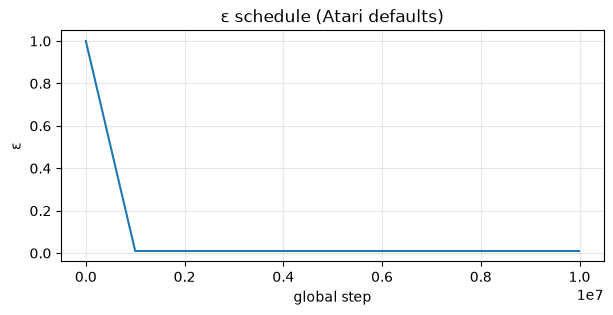

In [29]:
def linear_schedule(start_e: float, end_e: float, duration: int, t: int):
    slope = (end_e - start_e) / duration
    return max(slope * t + start_e, end_e)

a = Args()
steps = np.arange(0, a.total_timesteps, 10_000)
plt.figure(figsize=(7, 3))
plt.plot(steps, [linear_schedule(a.start_e, a.end_e, a.exploration_fraction * a.total_timesteps, t) for t in steps])
plt.xlabel("global step"); plt.ylabel("ε"); plt.title("ε schedule (Atari defaults)"); plt.grid(alpha=.3); plt.show()

## 5. The DQN training loop

This mirrors the main loop of CleanRL's `dqn_atari.py`. Every environment step:

1. **Act** ε-greedily with the online network $Q_\theta$.
2. **Step** the environment and **store** $(s, a, r, s', \text{terminated})$ in the replay buffer.
3. After `learning_starts` steps, every `train_frequency` steps:
   - sample a mini-batch,
   - compute the TD target with the **target network** under `torch.no_grad()`,
   - take a gradient step on the MSE between $Q_\theta(s,a)$ and the target.
4. Every `target_network_frequency` steps, update the target network:
   $\theta^- \leftarrow \tau\,\theta + (1-\tau)\,\theta^-$. With $\tau = 1$ this is a plain copy.

Two notes compared with the original file:
- CleanRL wraps the environment in a `SyncVectorEnv` (with only one env). Vector envs reset automatically, so the
  real final observation is hidden in `infos["final_observation"]`. With a **single** Gymnasium environment,
  `step()` returns the true final observation directly and we call `reset()` ourselves, so no workaround is needed.
- `obs = next_obs`, which CleanRL marks *"CRUCIAL step easy to overlook"*, is still here.

In [30]:
def train_dqn(args, env, QNet, log_interval=50_000):
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)

    q_network = QNet(env).to(device)
    optimizer = optim.Adam(q_network.parameters(), lr=args.learning_rate)
    target_network = QNet(env).to(device)
    target_network.load_state_dict(q_network.state_dict())        # start as an exact copy

    rb = ReplayBuffer(args.buffer_size, env.observation_space.shape, env.observation_space.dtype,
                      device, args.optimize_memory_usage)
    log = defaultdict(list)
    start_time = time.time()

    env.action_space.seed(args.seed)
    obs, _ = env.reset(seed=args.seed)
    for global_step in range(args.total_timesteps):
        # 1) act epsilon-greedily
        epsilon = linear_schedule(args.start_e, args.end_e,
                                  args.exploration_fraction * args.total_timesteps, global_step)
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                q_values = q_network(torch.as_tensor(np.asarray(obs), device=device).float().unsqueeze(0))
            action = int(q_values.argmax(dim=1))

        # 2) step the environment and store the transition
        next_obs, reward, terminated, truncated, info = env.step(action)
        rb.add(obs, next_obs, action, reward, terminated)
        obs = next_obs                                             # CRUCIAL step easy to overlook

        if terminated or truncated:
            if "episode" in info:                                  # a real game ended (RecordEpisodeStatistics)
                log["episode_step"].append(global_step)
                log["episode_return"].append(float(info["episode"]["r"]))
            obs, _ = env.reset()

        # 3) learn
        if global_step > args.learning_starts:
            if global_step % args.train_frequency == 0:
                b_obs, b_actions, b_next_obs, b_rewards, b_dones = rb.sample(args.batch_size)
                with torch.no_grad():                              # targets from the FROZEN network
                    target_max, _ = target_network(b_next_obs).max(dim=1)
                    td_target = b_rewards + args.gamma * target_max * (1 - b_dones)
                old_val = q_network(b_obs).gather(1, b_actions).squeeze(1)   # Q(s, a) for the taken actions
                loss = F.mse_loss(td_target, old_val)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                if global_step % 100 == 0:
                    log["train_step"].append(global_step)
                    log["td_loss"].append(loss.item())
                    log["q_value"].append(old_val.mean().item())

            # 4) update the target network
            if global_step % args.target_network_frequency == 0:
                for target_param, q_param in zip(target_network.parameters(), q_network.parameters()):
                    target_param.data.copy_(args.tau * q_param.data + (1.0 - args.tau) * target_param.data)

        if log_interval and global_step > 0 and global_step % log_interval == 0:
            recent = log["episode_return"][-20:]
            sps = int(global_step / (time.time() - start_time))
            print(f"step {global_step:>8,} | ε={epsilon:.2f} | avg return (last 20) "
                  f"{np.mean(recent) if recent else float('nan'):7.1f} | SPS {sps}")

    return q_network, log

`gather(1, actions)` picks, for each row of the batch, the Q-value of the action that was actually taken:

```
q_network(obs)  = [[0.1, 0.7],      actions = [[1],     ->  old_val = [0.7,
                   [0.4, 0.2]]                 [0]]                    0.4]
```

Next come two helpers: one to evaluate a trained agent and one to plot the training logs.

In [31]:
def evaluate(env, q_network, episodes=10, epsilon=0.0, seed=10_000):
    '''Average return of the (almost) greedy policy over full games.'''
    returns, done_games = [], 0
    obs, _ = env.reset(seed=seed)
    while done_games < episodes:
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                action = int(q_network(torch.as_tensor(np.asarray(obs), device=device).float().unsqueeze(0)).argmax())
        obs, _, terminated, truncated, info = env.step(action)
        if terminated or truncated:
            if "episode" in info:
                returns.append(float(info["episode"]["r"]))
                done_games += 1
            obs, _ = env.reset()
    return np.array(returns)


def plot_training(log, title, window=20):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    r = np.array(log["episode_return"])
    ax[0].plot(log["episode_step"], r, alpha=0.25, label="episode")
    if len(r) >= window:
        ax[0].plot(log["episode_step"][window - 1:], np.convolve(r, np.ones(window) / window, "valid"),
                   label=f"rolling mean ({window})")
    ax[0].set(title="episodic return", xlabel="global step"); ax[0].legend()
    ax[1].plot(log["train_step"], log["td_loss"]); ax[1].set(title="TD loss", xlabel="global step", yscale="log")
    ax[2].plot(log["train_step"], log["q_value"]); ax[2].set(title="mean Q(s, a) of batch", xlabel="global step")
    fig.suptitle(title); plt.tight_layout(); plt.show()

# Part A: DQN on CartPole

Balance a pole on a cart by pushing left or right. The reward is +1 per step, and episodes are capped at
500 steps, so 500 is a perfect score. The settings below match CleanRL's `dqn.py` (its CartPole version).
This takes roughly 2–4 minutes on a CPU.

step   50,000 | ε=0.81 | avg return (last 20)    30.2 | SPS 34360
step  100,000 | ε=0.62 | avg return (last 20)    73.6 | SPS 30151
step  150,000 | ε=0.43 | avg return (last 20)   167.7 | SPS 28031
step  200,000 | ε=0.24 | avg return (last 20)   309.8 | SPS 26597
step  250,000 | ε=0.05 | avg return (last 20)   500.0 | SPS 25465
step  300,000 | ε=0.05 | avg return (last 20)   467.8 | SPS 24682
step  350,000 | ε=0.05 | avg return (last 20)   444.3 | SPS 24145
step  400,000 | ε=0.05 | avg return (last 20)   495.1 | SPS 23766
step  450,000 | ε=0.05 | avg return (last 20)   500.0 | SPS 23492


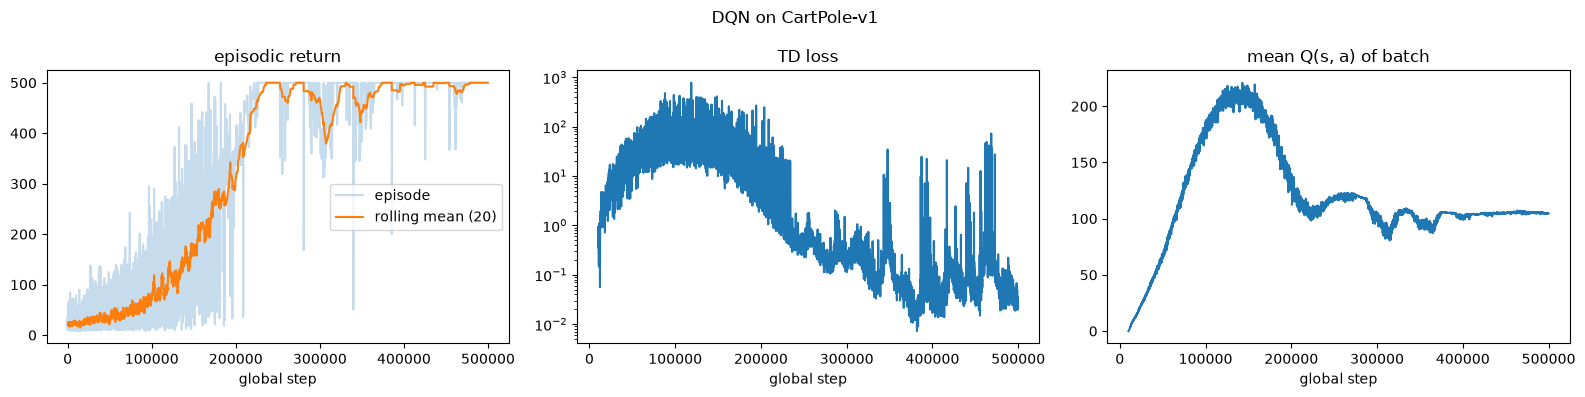

In [32]:
cartpole_args = replace(
    Args(),
    env_id="CartPole-v1",
    total_timesteps=500_000,
    learning_rate=2.5e-4,
    buffer_size=10_000,
    target_network_frequency=500,
    batch_size=128,
    end_e=0.05,
    exploration_fraction=0.5,
    learning_starts=10_000,
    train_frequency=10,
    optimize_memory_usage=False,      # CartPole episodes get truncated, so store next_obs explicitly
)

cp_env = gym.wrappers.RecordEpisodeStatistics(gym.make(cartpole_args.env_id))
cp_q, cp_log = train_dqn(cartpole_args, cp_env, MLPQNetwork)
plot_training(cp_log, "DQN on CartPole-v1")

**Reading the plots**
- **Returns** stay low while ε is high, because the agent is mostly random. They climb as ε decays over the first
  250k steps, then reach the 500 cap and stay there.
- **TD loss** behaves nothing like a supervised loss. It *rises* during learning, because the targets grow as the
  policy improves and every target-network sync shifts them. It only falls once the policy stops changing.
- **Mean Q** is the most instructive plot. With γ = 0.99 and +1 per step, no state can be worth more than
  $\sum_t 0.99^t = 1/(1-0.99) = 100$. Yet the Q-values overshoot to about **215** before settling near 100.
  This is DQN's **overestimation bias**: the `max` in the target always picks whichever action's value is
  currently overestimated, and bootstrapping feeds that error back into itself.
  Here it corrects itself, but in harder environments it can destabilize training.
  Double DQN, at the end of this notebook, was designed to fix exactly this.

In [33]:
cp_eval_env = gym.wrappers.RecordEpisodeStatistics(gym.make("CartPole-v1"))
returns = evaluate(cp_eval_env, cp_q, episodes=20, epsilon=0.0)
print(f"greedy policy over 20 episodes: mean {returns.mean():.1f}, min {returns.min():.0f}, max {returns.max():.0f}")

greedy policy over 20 episodes: mean 500.0, min 500, max 500


# Part B: DQN on Atari (Breakout)

The algorithm is unchanged. What changes is the **input pipeline**. Raw Atari frames are 210×160 RGB at 60 fps,
so DQN uses a stack of preprocessing wrappers, the ones `make_env` applies in CleanRL:

| Wrapper | What it does | Why |
|---|---|---|
| `RecordEpisodeStatistics` | records the raw game score and length | logging the *true* score, before clipping |
| `NoopResetEnv(30)` | 1–30 random no-op actions after reset | random start states, so the agent can't memorize one sequence |
| `MaxAndSkipEnv(4)` | repeat each action 4 frames, max over the last 2 | 4× fewer decisions; max removes Atari sprite flicker |
| `EpisodicLifeEnv` | losing a life counts as `terminated` | the agent learns that losing a life is bad |
| `FireResetEnv` | press FIRE after reset | Breakout does nothing until FIRE launches the ball |
| `ClipRewardEnv` | reward → sign(reward) ∈ {−1, 0, +1} | one learning rate works across games with different scales |
| `ResizeObservation(84,84)` + `GrayscaleObservation` | 210×160×3 → 84×84 | about 20× less input |
| `FrameStackObservation(4)` | stack the last 4 frames | velocity information |

CleanRL imports the first five from `cleanrl_utils.atari_wrappers`, and their implementations follow
Stable-Baselines3's. They are written out below so the notebook is self-contained.
The last three are built into Gymnasium. Note that Gymnasium 1.x renamed `GrayScaleObservation` → `GrayscaleObservation`
and `FrameStack` → `FrameStackObservation`; the CleanRL file still uses the old names.

In [34]:
import ale_py
gym.register_envs(ale_py)          # makes the Atari environments available to gym.make


class NoopResetEnv(gym.Wrapper):
    def __init__(self, env, noop_max=30):
        super().__init__(env)
        self.noop_max = noop_max

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        for _ in range(self.unwrapped.np_random.integers(1, self.noop_max + 1)):
            obs, _, terminated, truncated, info = self.env.step(0)       # 0 = NOOP
            if terminated or truncated:
                obs, info = self.env.reset()
        return obs, info


class MaxAndSkipEnv(gym.Wrapper):
    def __init__(self, env, skip=4):
        super().__init__(env)
        self.skip = skip
        self.frames = np.zeros((2, *env.observation_space.shape), dtype=env.observation_space.dtype)

    def step(self, action):
        total_reward = 0.0
        for i in range(self.skip):
            obs, reward, terminated, truncated, info = self.env.step(action)
            if i >= self.skip - 2:
                self.frames[i - (self.skip - 2)] = obs
            total_reward += reward
            if terminated or truncated:
                break
        return self.frames.max(axis=0), total_reward, terminated, truncated, info


class EpisodicLifeEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.lives, self.real_done = 0, True

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        self.real_done = terminated or truncated
        lives = self.unwrapped.ale.lives()
        if 0 < lives < self.lives:
            terminated = True                     # life lost: end of "episode" for learning
        self.lives = lives
        return obs, reward, terminated, truncated, info

    def reset(self, **kwargs):
        if self.real_done:                        # real game over: actually reset
            obs, info = self.env.reset(**kwargs)
        else:                                     # just a lost life: keep playing
            obs, _, _, _, info = self.env.step(0)
        self.lives = self.unwrapped.ale.lives()
        return obs, info


class FireResetEnv(gym.Wrapper):
    def reset(self, **kwargs):
        self.env.reset(**kwargs)
        obs, _, terminated, truncated, _ = self.env.step(1)              # 1 = FIRE
        if terminated or truncated:
            self.env.reset(**kwargs)
        obs, _, terminated, truncated, info = self.env.step(2)
        if terminated or truncated:
            self.env.reset(**kwargs)
        return obs, info


class ClipRewardEnv(gym.RewardWrapper):
    def reward(self, reward):
        return float(np.sign(reward))


def make_atari_env(env_id, seed):
    env = gym.make(env_id)
    env = gym.wrappers.RecordEpisodeStatistics(env)
    env = NoopResetEnv(env, noop_max=30)
    env = MaxAndSkipEnv(env, skip=4)
    env = EpisodicLifeEnv(env)
    if "FIRE" in env.unwrapped.get_action_meanings():
        env = FireResetEnv(env)
    env = ClipRewardEnv(env)
    env = gym.wrappers.ResizeObservation(env, (84, 84))
    env = gym.wrappers.GrayscaleObservation(env)
    env = gym.wrappers.FrameStackObservation(env, 4)
    env.action_space.seed(seed)
    return env

### What the network actually sees

raw frame: (210, 160, 3) uint8 | processed observation: (4, 84, 84) uint8
actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


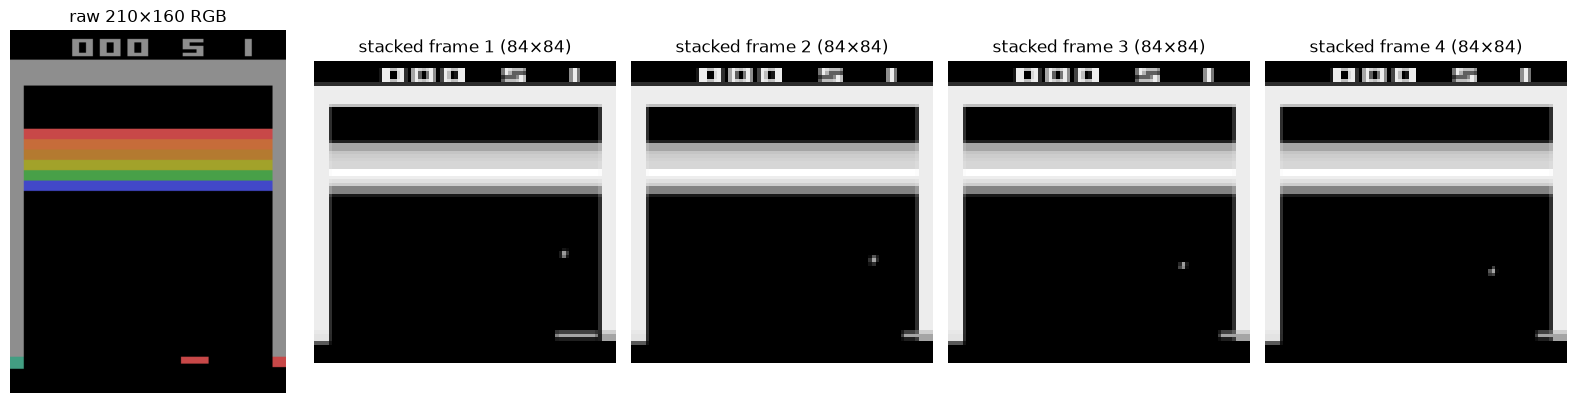

In [35]:
atari_args = Args()                                   # CleanRL's Atari defaults
raw_env = gym.make(atari_args.env_id)
raw_obs, _ = raw_env.reset(seed=0)

env = make_atari_env(atari_args.env_id, atari_args.seed)
obs, _ = env.reset(seed=0)
for a in [2, 2, 2, 3]:                                # move a bit so the frames differ
    obs, *_ = env.step(a)

print("raw frame:", raw_obs.shape, raw_obs.dtype, "| processed observation:", obs.shape, obs.dtype)
print("actions:", env.unwrapped.get_action_meanings())

fig, ax = plt.subplots(1, 5, figsize=(16, 4))
ax[0].imshow(raw_obs); ax[0].set_title("raw 210×160 RGB")
for i in range(4):
    ax[i + 1].imshow(obs[i], cmap="gray"); ax[i + 1].set_title(f"stacked frame {i + 1} (84×84)")
for a_ in ax:
    a_.axis("off")
plt.tight_layout(); plt.show()

### Training

The full CleanRL run is **10 million steps** (40M game frames). On a GPU that takes many hours; on a CPU it
would take days, so it's switched off by default. Memory: even with `optimize_memory_usage`, a 1M-transition
buffer needs about **28 GB of RAM**. On a typical machine or Colab, use `buffer_size=100_000` (about 3 GB).
That learns somewhat worse, but it works.

The cell below always runs a **short smoke test**, a few thousand steps, to check that everything is wired correctly.
Set `RUN_FULL_TRAINING = True` for the real run.

In [36]:
RUN_FULL_TRAINING = False

if RUN_FULL_TRAINING:
    run_args = replace(atari_args, buffer_size=100_000)      # lower than CleanRL's 1M to fit in RAM
    log_interval = 100_000
else:
    run_args = replace(atari_args, total_timesteps=3_000, learning_starts=1_000, buffer_size=3_000)
    log_interval = 1_000

atari_env = make_atari_env(run_args.env_id, run_args.seed)
atari_q, atari_log = train_dqn(run_args, atari_env, QNetwork, log_interval=log_interval)
print(f"\nfinished {run_args.total_timesteps:,} steps | games played: {len(atari_log['episode_return'])} "
      f"| gradient steps logged: {len(atari_log['td_loss'])}")

if RUN_FULL_TRAINING:
    plot_training(atari_log, f"DQN on {run_args.env_id}", window=100)
    torch.save(atari_q.state_dict(), "dqn_breakout.pt")

step    1,000 | ε=0.01 | avg return (last 20)     2.6 | SPS 1330
step    2,000 | ε=0.01 | avg return (last 20)     2.3 | SPS 253

finished 3,000 steps | games played: 16 | gradient steps logged: 19


In [37]:
# Evaluate like CleanRL does: 10 full games with a small epsilon (end_e)
eval_returns = evaluate(make_atari_env(run_args.env_id, seed=123), atari_q, episodes=10 if RUN_FULL_TRAINING else 3,
                        epsilon=run_args.end_e)
print("evaluation returns (raw game score):", eval_returns)

evaluation returns (raw game score): [2. 2. 2.]


After the 3,000-step smoke test these scores are close to random play, which is expected. A real Breakout agent
needs millions of steps. Even then, the learning curve typically stays flat for a long time before scores take off.

## Summary

DQN = **Q-learning** + **a neural network** + **experience replay** + **a target network**.

- The loss is a regression onto $r + \gamma(1-\text{done})\max_{a'} Q_{\theta^-}(s',a')$, with no gradient through the target.
- Replay breaks the correlation between samples and reuses experience. The target network keeps the regression
  target still for `target_network_frequency` steps.
- Only *true* terminations stop bootstrapping. Truncations should bootstrap.

## Next steps

**Double DQN** (van Hasselt et al., 2016). The `max` in the target picks actions whose Q-values happen to be
overestimated, so DQN is systematically **optimistic**. The fix is to choose the action with the online network
and evaluate it with the target network. It is a two-line change in `train_dqn`:

```python
with torch.no_grad():
    best_actions = q_network(b_next_obs).argmax(dim=1, keepdim=True)            # online net CHOOSES
    target_q = target_network(b_next_obs).gather(1, best_actions).squeeze(1)   # target net EVALUATES
    td_target = b_rewards + args.gamma * target_q * (1 - b_dones)
```

**Further ideas to try**
- **Ablations on CartPole:** set `target_network_frequency=1` (effectively no target network) or `buffer_size=batch_size`
  (effectively no replay) and watch training become unstable.
- **Huber loss:** `F.smooth_l1_loss` instead of MSE, as in the original paper, is more robust to large TD errors.
- **Other improvements:** dueling networks, prioritized replay and n-step returns. Combined with Double DQN they form
  **Rainbow**. CleanRL also has `c51_atari.py` (distributional RL) and `qdagger_dqn_atari_impalacnn.py`.